# DashExplain: Car Dashboard Warning Light Recognition and Explanation

Upload a photo of a dashboard (or a single warning icon) and this notebook will:
1. find the glowing icons with **OpenCV**,
2. read each icon's **colour** (red / amber / green),
3. identify the symbol with an **AI model (CLIP)**,
4. explain it in plain language and answer your questions (**NLP**).

**Run the cells from top to bottom.** Cells marked *Optional* make it more accurate.

> Educational aid only. Always follow your vehicle manual and a qualified mechanic. Treat red lights as "stop and check".

## Step 1: Setup

In [1]:
!pip install -q transformers

import os, cv2, numpy as np, torch
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Setup OK | running on:", device)

Setup OK | running on: cuda


## Step 2: Knowledge base
One entry per warning symbol. `desc` is a plain-English description of how the symbol *looks*. The AI model uses it to recognise the symbol. The other fields are what the user reads.

In [2]:
KB = {
    "check_engine": {
        "name": "Check Engine Light", "desc": "an engine outline", "level": "Medium",
        "meaning": "The engine or emissions system has detected a fault.",
        "action": "Reduce speed and get the car scanned by a mechanic soon. If the light is FLASHING, stop driving and call for help.",
        "avoid": "Do not ignore it for weeks, and do not drive hard if it is flashing."},
    "oil_pressure": {
        "name": "Oil Pressure Warning", "desc": "an old-fashioned oil can with a drip", "level": "High",
        "meaning": "Engine oil pressure is too low. The engine may be damaged quickly without enough oil.",
        "action": "Pull over safely, switch off the engine and check the oil level. If the oil is low, do not restart. Call for assistance.",
        "avoid": "Do not keep driving, even for a short distance."},
    "battery": {
        "name": "Battery / Charging Warning", "desc": "a car battery with plus and minus signs", "level": "High",
        "meaning": "The charging system (alternator or battery) is not working properly.",
        "action": "Switch off non-essential electricals (AC, music) and go straight to a garage. The car may stall when the battery drains.",
        "avoid": "Do not switch the engine off until you are somewhere safe, because it may not restart."},
    "coolant_temp": {
        "name": "Engine Temperature Warning", "desc": "a thermometer dipping into wavy lines of liquid", "level": "High",
        "meaning": "The engine coolant is too hot, so the engine is overheating.",
        "action": "Stop safely, switch off the engine and let it cool for at least 30 minutes. Check the coolant level only when the engine is cool.",
        "avoid": "Never open the radiator cap on a hot engine."},
    "brake": {
        "name": "Brake System Warning", "desc": "an exclamation mark inside a circle with brackets on both sides", "level": "High",
        "meaning": "The parking brake is on, brake fluid is low, or there is a brake system fault.",
        "action": "Check that the handbrake is fully released. If the light stays on, stop safely and have the brakes inspected before driving.",
        "avoid": "Do not keep driving with a possible braking fault."},
    "abs": {
        "name": "ABS Warning", "desc": "the letters ABS inside a circle", "level": "Medium",
        "meaning": "The Anti-lock Braking System has a fault. Normal brakes usually still work, but without anti-lock help.",
        "action": "Drive carefully, brake gently and early, and get the ABS checked soon.",
        "avoid": "Do not brake hard on wet or slippery roads."},
    "tpms": {
        "name": "Tyre Pressure Warning", "desc": "a flat tyre cross-section with an exclamation mark", "level": "Medium",
        "meaning": "One or more tyres have low pressure.",
        "action": "Check and inflate all tyres to the recommended pressure, and look for punctures or damage.",
        "avoid": "Do not drive at high speed on a visibly flat or soft tyre."},
    "airbag": {
        "name": "Airbag Warning", "desc": "a seated person with a large circle in front of them", "level": "High",
        "meaning": "There is a fault in the airbag or seat-belt system, so airbags may not open in a crash.",
        "action": "Get the system inspected at a service centre soon.",
        "avoid": "Do not ignore it. The airbags may not protect you in an accident."},
    "seatbelt": {
        "name": "Seat Belt Reminder", "desc": "a person wearing a diagonal seat belt", "level": "Low",
        "meaning": "A seat belt is not fastened.",
        "action": "Fasten all seat belts.",
        "avoid": "Do not drive with unfastened seat belts."},
    "low_fuel": {
        "name": "Low Fuel Warning", "desc": "a fuel pump", "level": "Low",
        "meaning": "The fuel level is low.",
        "action": "Refuel at the nearest petrol pump.",
        "avoid": "Do not run the tank completely empty. It can damage the fuel pump."},
}

CLASSES = list(KB.keys()) + ["unknown"]   # "unknown" = not one of our warning lights
print(len(KB), "warning symbols in the knowledge base")

10 warning symbols in the knowledge base


## Step 3: Load the AI model (CLIP)
CLIP understands both images and text, so it can match a photo to a *description* without us training anything.
`clip-vit-large-patch14` is the most accurate. If it is too slow, change it to `openai/clip-vit-base-patch32`.

In [3]:
MODEL_NAME = "openai/clip-vit-large-patch14"

model = CLIPModel.from_pretrained(MODEL_NAME).to(device).eval()
processor = CLIPProcessor.from_pretrained(MODEL_NAME)

def _features(out):
    return out if torch.is_tensor(out) else out.pooler_output

@torch.no_grad()
def embed_images(pil_images):
    inputs = processor(images=pil_images, return_tensors="pt").to(device)
    f = _features(model.get_image_features(**inputs))
    return torch.nn.functional.normalize(f, dim=-1)

@torch.no_grad()
def embed_texts(texts):
    inputs = processor(text=texts, return_tensors="pt", padding=True).to(device)
    f = _features(model.get_text_features(**inputs))
    return torch.nn.functional.normalize(f, dim=-1)

# Several sentence styles per symbol, averaged, give steadier results than one label.
TEMPLATES = [
    "a car dashboard warning light showing {}",
    "a close-up photo of a dashboard warning symbol: {}",
    "an icon of {}",
]
UNKNOWN_TEXTS = [
    "a car dashboard with no warning lights on",
    "a random photo that is not a warning symbol",
    "a plain dark background",
]

rows = []
for c in CLASSES:
    texts = UNKNOWN_TEXTS if c == "unknown" else [t.format(KB[c]["desc"]) for t in TEMPLATES]
    v = embed_texts(texts).mean(dim=0)
    rows.append(torch.nn.functional.normalize(v, dim=-1))
text_matrix = torch.stack(rows)                 # (num_classes, dim)
logit_scale = model.logit_scale.exp().item()    # about 100

def zero_shot_probs(img_emb):
    return (logit_scale * img_emb @ text_matrix.T).softmax(dim=-1).cpu().numpy()

fewshot_clf = None   # filled in by the optional cell near the end

def predict_probs(pil_images):
    emb = embed_images(pil_images)
    p = zero_shot_probs(emb)
    if fewshot_clf is not None:                 # blend with the model trained on YOUR images
        q = np.zeros_like(p)
        proba = fewshot_clf.predict_proba(emb.cpu().numpy())
        for j, cls in enumerate(fewshot_clf.classes_):
            q[:, CLASSES.index(cls)] = proba[:, j]
        p = 0.4 * p + 0.6 * q
    return p

print("AI model ready.")

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

AI model ready.


## Step 4: OpenCV helpers
- `find_icon_regions` finds bright, coloured blobs (glowing icons) so a photo with several lights is analysed icon by icon.
- `dominant_colour` reads the icon colour in HSV. Red means urgent, amber means check soon, green or blue means information.

In [4]:
def resize_max(bgr, max_side=1280):
    h, w = bgr.shape[:2]
    s = max_side / max(h, w)
    return cv2.resize(bgr, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA) if s < 1 else bgr

def find_icon_regions(bgr, max_regions=6):
    h, w = bgr.shape[:2]
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    mask = ((hsv[..., 2] > 150) & (hsv[..., 1] > 90)).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))   # join thin strokes
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    cands = []
    for c in contours:
        x, y, bw, bh = cv2.boundingRect(c)
        area = bw * bh
        if area < 0.0005 * h * w or area > 0.25 * h * w:   # too tiny, or too big to be one icon
            continue
        if not (0.3 < bw / bh < 3.5):
            continue
        pad = int(0.25 * max(bw, bh))
        cands.append((area, (max(0, x - pad), max(0, y - pad), min(w, x + bw + pad), min(h, y + bh + pad))))

    cands.sort(key=lambda t: t[0], reverse=True)
    boxes = []
    for _, (x1, y1, x2, y2) in cands:
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        if any(a <= cx <= c_ and b <= cy <= d for a, b, c_, d in boxes):   # skip boxes inside others
            continue
        boxes.append((x1, y1, x2, y2))
    return boxes[:max_regions]

def dominant_colour(bgr_crop):
    hsv = cv2.cvtColor(bgr_crop, cv2.COLOR_BGR2HSV)
    hue, sat, val = cv2.split(hsv)
    lit = (sat > 90) & (val > 140)
    if lit.sum() < 30:
        return "unclear", 0.0
    hues = hue[lit]
    counts = {
        "red":   int(((hues <= 10) | (hues >= 165)).sum()),
        "amber": int(((hues > 10) & (hues <= 35)).sum()),
        "green": int(((hues > 35) & (hues <= 85)).sum()),
        "blue":  int(((hues > 85) & (hues <= 135)).sum()),
    }
    name = max(counts, key=counts.get)
    return name, counts[name] / int(lit.sum())

## Step 5: The DashExplain engine
Combines everything. The final severity is the **higher** of the symbol's usual level and what the colour says (a red light is never downgraded). If the model is not confident, it says so instead of guessing.

In [5]:
LEVEL_RANK = {"Low": 0, "Medium": 1, "High": 2}
COLOUR_LEVEL = {"red": "High", "amber": "Medium", "green": "Low", "blue": "Low"}
COLOUR_MEANING = {
    "red": "red = serious, stop and check",
    "amber": "amber = check soon",
    "green": "green = information / system on",
    "blue": "blue = information / system on",
    "unclear": "colour unclear",
}

def final_level(label, colour):
    base = KB[label]["level"]
    from_colour = COLOUR_LEVEL.get(colour, base)
    return max(base, from_colour, key=lambda lv: LEVEL_RANK[lv])

def print_report(i, r):
    print(f"--- Light {i} ---")
    if not r["confident"]:
        print("Not sure what this is. Please check your vehicle manual.")
        guesses = ", ".join(f"{KB[c]['name']} ({p*100:.0f}%)" for c, p in r["top3"] if c != "unknown")
        print("Closest guesses:", guesses, "\n")
        return
    k = KB[r["label"]]
    print(f"Detected   : {k['name']}  (confidence {r['conf']*100:.0f}%)")
    print(f"Colour     : {COLOUR_MEANING[r['colour']]}")
    print(f"Severity   : {r['level'].upper()}")
    print(f"Meaning    : {k['meaning']}")
    print(f"What to do : {k['action']}")
    print(f"Avoid      : {k['avoid']}\n")

def run_dashexplain(image_path, conf_threshold=0.50, max_regions=6):
    bgr = cv2.imread(image_path)
    if bgr is None:
        print("Could not read that image. Please upload a .jpg or .png file.")
        return []
    bgr = resize_max(bgr)
    boxes = find_icon_regions(bgr, max_regions)
    if not boxes:
        print("No separate glowing icons found, so the whole image is analysed.\n")
        boxes = [(0, 0, bgr.shape[1], bgr.shape[0])]

    crops = [bgr[y1:y2, x1:x2] for x1, y1, x2, y2 in boxes]
    pils = [Image.fromarray(cv2.cvtColor(c, cv2.COLOR_BGR2RGB)) for c in crops]
    probs = predict_probs(pils)

    results = []
    for box, crop, p in zip(boxes, crops, probs):
        order = np.argsort(p)[::-1]
        label, conf = CLASSES[order[0]], float(p[order[0]])
        colour, _ = dominant_colour(crop)
        confident = label != "unknown" and conf >= conf_threshold
        results.append({
            "box": box, "label": label, "conf": conf, "colour": colour, "confident": confident,
            "level": final_level(label, colour) if label != "unknown" else None,
            "top3": [(CLASSES[j], float(p[j])) for j in order[:3]],
        })

    vis = bgr.copy()
    for i, r in enumerate(results, 1):
        x1, y1, x2, y2 = r["box"]
        col = (0, 200, 0) if r["confident"] else (0, 0, 255)
        cv2.rectangle(vis, (x1, y1), (x2, y2), col, 3)
        cv2.putText(vis, str(i), (x1 + 4, y1 + 30), cv2.FONT_HERSHEY_SIMPLEX, 1.0, col, 2)
    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("Green box = recognised, red box = not sure")
    plt.show()

    print("========== DashExplain ==========")
    for i, r in enumerate(results, 1):
        print_report(i, r)
    print("Educational aid only. Follow your vehicle manual and consult a mechanic.")
    print("=================================")
    return results

## Step 6: Try it. Upload a dashboard photo or a single warning icon

Saving abs-warning-light-1-1024x683.jpg.webp to abs-warning-light-1-1024x683.jpg.webp


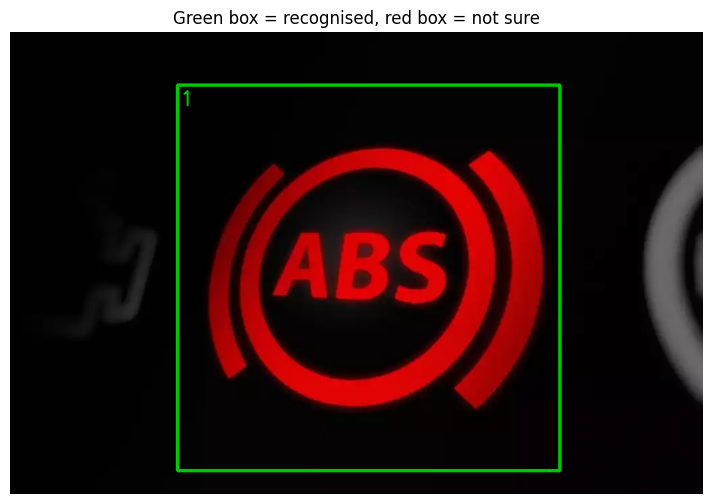

========== DashExplain ==========
--- Light 1 ---
Detected   : ABS Warning  (confidence 100%)
Colour     : red = serious, stop and check
Severity   : HIGH
Meaning    : The Anti-lock Braking System has a fault. Normal brakes usually still work, but without anti-lock help.
What to do : Drive carefully, brake gently and early, and get the ABS checked soon.
Avoid      : Do not brake hard on wet or slippery roads.

Educational aid only. Follow your vehicle manual and consult a mechanic.


In [6]:
uploaded = files.upload()
image_path = list(uploaded.keys())[0]
results = run_dashexplain(image_path)

## Step 7: Ask questions (NLP)
Your question is matched to the closest known question type using TF-IDF similarity, so "can I keep going?" and "is it safe to drive?" both work. The answer is built from the symbol that was detected.
Type your question, or just press Enter to stop.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

INTENTS = {
    "meaning": ["what does this light mean", "what is this warning", "why is this light on",
                "explain this symbol", "what is wrong with my car", "what is this"],
    "drive":   ["can i keep driving", "can i drive", "is it safe to drive", "is it safe to drive the car",
                "should i stop the car", "can i continue my journey", "will the car break down",
                "is it dangerous", "is it serious", "is it urgent"],
    "action":  ["what should i do", "how do i fix this", "how to fix", "what is the solution",
                "what to do next", "how to solve this", "do i need a mechanic"],
    "avoid":   ["what should i not do", "what should i avoid", "what are the dangers",
                "what mistakes to avoid", "what not to do"],
}
_qs, _labels = [], []
for intent, qs in INTENTS.items():
    _qs += qs
    _labels += [intent] * len(qs)
_STOP = ["the", "is", "a", "an", "to", "of", "it", "my", "this", "i", "what", "are"]
_vec = TfidfVectorizer(stop_words=_STOP).fit(_qs)
_Q = _vec.transform(_qs)

def ask(question, result):
    k = KB[result["label"]]
    sims = cosine_similarity(_vec.transform([question.lower()]), _Q)[0]
    best = int(sims.argmax())
    if sims[best] < 0.3:
        return "I can answer: what it means, whether you can keep driving, what to do, and what to avoid."
    intent = _labels[best]
    if intent == "meaning":
        return k["meaning"]
    if intent == "action":
        return k["action"]
    if intent == "avoid":
        return k["avoid"]
    lv = result["level"]
    if lv == "High":
        return "Not recommended. Stop safely as soon as you can. " + k["action"]
    if lv == "Medium":
        return "Only drive carefully as far as needed to get it checked, and stop if the light flashes or the car behaves oddly. " + k["action"]
    return "Usually yes, but please act on it. " + k["action"]

def chat(results):
    ok = [r for r in results if r["confident"]]
    if not ok:
        print("No confident detection to ask about. Try a clearer photo.")
        return
    focus = max(ok, key=lambda r: r["conf"])
    print("Asking about:", KB[focus["label"]]["name"])
    while True:
        q = input("Your question (Enter to stop): ").strip()
        if not q:
            break
        print("DashExplain:", ask(q, focus), "\n")

chat(results)

Asking about: ABS Warning
Your question (Enter to stop): action
DashExplain: I can answer: what it means, whether you can keep driving, what to do, and what to avoid. 

Your question (Enter to stop): driving
DashExplain: Not recommended. Stop safely as soon as you can. Drive carefully, brake gently and early, and get the ABS checked soon. 

Your question (Enter to stop): 
